# Ingeniería de características para segmentación de inundaciones en Perú

**Avance semana 5.** Autores: Gerson Andre Garrido Mansilla y Renzo Elvis Cerron Tome
(Maestría en Ciencias con mención en IA, UNI).

**Contexto de la tesis.** El objetivo es segmentar áreas inundadas en imágenes Sentinel-2 de
Perú. Se comparan dos modelos fundacionales geoespaciales (TerraMind v1-B y
Prithvi-EO-2.0 300M) con una U-Net de referencia. Datos:
- Sen1Floods11, con sus particiones oficiales;
- Perú 2023, con etiquetas UNOSAT;
- Perú 2017, con etiquetas Copernicus EMS.

Los modelos profundos reciben reflectancia cruda y aprenden sus propias características. En
este cuaderno se estudia de forma explícita **qué aportan las características diseñadas**: los
índices espectrales y el contexto espacial local. Para ello se usa un clasificador clásico por
píxel (*gradient boosting*), en dos escenarios:
- **(a)** entrenado con etiquetas de Perú (`peru-train`);
- **(b)** entrenado solo con Sen1Floods11 y aplicado a Perú. Es el escenario sin etiquetas
  peruanas que estudia la tesis.

**Protocolo.** Toda la evaluación se hace en `peru-dev`, la partición de selección. Las
particiones de prueba (`peru-test`, `peru-2017-test`) no se leen. Este trabajo es exploratorio
y no modifica la comparación final de la tesis.

El inventario completo de la ingeniería de características que ya usa el proyecto está en
`docs/feature_engineering.md`. Incluye la selección de bandas por modelo, la normalización
oficial, la armonización radiométrica, la igualación de histogramas, FDA y el control de
calidad de etiquetas con MNDWI.

Código del experimento: `scripts/feature_engineering.py`.

In [1]:
import importlib.util, sys
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt, rasterio

REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(REPO / "src"))
spec = importlib.util.spec_from_file_location("fe", REPO / "scripts" / "feature_engineering.py")
fe = importlib.util.module_from_spec(spec); spec.loader.exec_module(fe)
%matplotlib inline
OUT = REPO / "outputs" / "feature_engineering"
pd.set_option("display.precision", 4)
print(len(fe.ALL), "características:", fe.ALL)

26 características: ['B01', 'B02', 'B03', 'B04', 'B05', 'B06', 'B07', 'B08', 'B8A', 'B09', 'B10', 'B11', 'B12', 'NDWI', 'MNDWI', 'MNDWI2', 'NDVI', 'NDMI', 'AWEI_nsh', 'AWEI_sh', 'WRI', 'MNDWI_mean3', 'MNDWI_mean7', 'MNDWI_std7', 'NIR_mean7', 'NDVI_mean7']


## 1. Características

Reflectancia r = ND / 10 000, con las 13 bandas L1C de Sentinel-2. Notación: G = B03 (verde),
R = B04 (rojo), NIR = B08, SWIR1 = B11, SWIR2 = B12.

| Grupo | Característica | Definición | Motivación |
|---|---|---|---|
| Bandas | B01–B12 (13) | Reflectancia cruda | Línea base: lo que reciben los modelos profundos |
| Índices | NDWI | (G − NIR)/(G + NIR) | El agua absorbe el NIR (McFeeters, 1996) |
| | MNDWI | (G − SWIR1)/(G + SWIR1) | El SWIR separa el agua del suelo construido o desnudo (Xu, 2006) |
| | MNDWI2 | (G − SWIR2)/(G + SWIR2) | Variante con SWIR2 |
| | NDVI | (NIR − R)/(NIR + R) | Vegetación; separa la vegetación del agua |
| | NDMI | (NIR − SWIR1)/(NIR + SWIR1) | Humedad del suelo y de la vegetación |
| | AWEI_nsh | 4(G − SWIR1) − (0.25 NIR + 2.75 SWIR2) | Índice de agua automatizado, sin sombras (Feyisa et al., 2014) |
| | AWEI_sh | B + 2.5G − 1.5(NIR + SWIR1) − 0.25 SWIR2 | Variante que suprime sombras |
| | WRI | (G + R)/(NIR + SWIR1) | Razón de agua |
| Contexto | MNDWI_mean3, MNDWI_mean7 | Media local de MNDWI en ventanas de 3×3 y 7×7 | Un píxel aislado no tiene contexto espacial |
| | MNDWI_std7 | Desviación estándar local de MNDWI en 7×7 | Textura; resalta bordes y ruido |
| | NIR_mean7, NDVI_mean7 | Media local en 7×7 | Entorno: vegetación o desierto |

Conjuntos comparados: `bands` (13), `indices` (8), `bands+indices` (21) y
`bands+indices+context` (26).

### Ejemplo visual en un recorte de `peru-dev`

Se elige el recorte de dev cuya fracción de agua está más cerca de 0.4, para que se vean agua y
suelo seco a la vez.

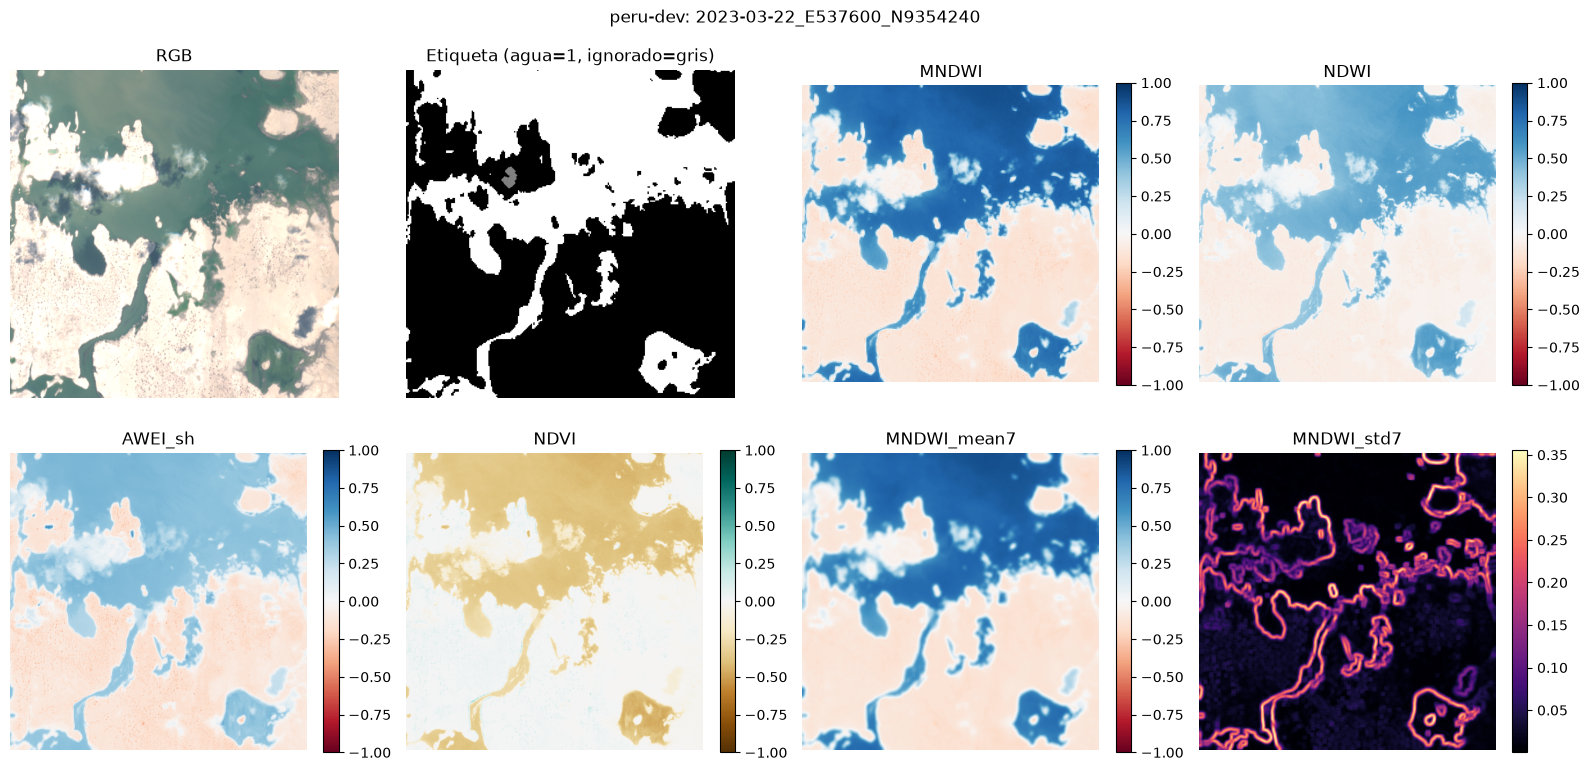

In [2]:
m = pd.read_csv(REPO / "data/peru/unosat2023/manifest.csv")
m["stem"] = m.date + "_" + m.chip
dev = set((REPO / "data/peru/unosat2023/splits/dev.txt").read_text().split())
d = m[m.stem.isin(dev)]
stem = d.loc[(d.water_frac - 0.4).abs().idxmin(), "stem"]
f, y, ok = fe.load(REPO / f"data/peru/unosat2023/s2/{stem}.tif", REPO / f"data/peru/unosat2023/label/{stem}.tif")
rgb = np.clip(f[[3, 2, 1]].transpose(1, 2, 0) / 0.3, 0, 1)
show = [("RGB", rgb, None), ("Etiqueta (agua=1, ignorado=gris)", np.where(y < 0, 0.5, y), "gray"),
        ("MNDWI", f[fe.ALL.index("MNDWI")], "RdBu"), ("NDWI", f[fe.ALL.index("NDWI")], "RdBu"),
        ("AWEI_sh", f[fe.ALL.index("AWEI_sh")], "RdBu"), ("NDVI", f[fe.ALL.index("NDVI")], "BrBG"),
        ("MNDWI_mean7", f[fe.ALL.index("MNDWI_mean7")], "RdBu"), ("MNDWI_std7", f[fe.ALL.index("MNDWI_std7")], "magma")]
fig, axs = plt.subplots(2, 4, figsize=(16, 8))
for ax, (t, a, cm) in zip(axs.flat, show):
    im = ax.imshow(a, cmap=cm, vmin=None if cm in (None, "gray", "magma") else -1, vmax=None if cm in (None, "gray", "magma") else 1)
    ax.set_title(t); ax.axis("off")
    if cm not in (None, "gray"): fig.colorbar(im, ax=ax, fraction=0.046)
fig.suptitle(f"peru-dev: {stem}"); plt.tight_layout(); plt.show()

## 2. Separabilidad univariada (AUROC)

Para cada característica se calcula el AUROC entre agua y suelo seco, es decir, qué tan bien la
característica sola ordena los píxeles de agua por encima de los secos. Se muestra
max(AUROC, 1 − AUROC), porque una característica que separa en sentido inverso es igual de útil.
Se compara en tres conjuntos: Sen1Floods11 `train`, `peru-train` y `peru-dev`.

Una característica es **robusta al cambio de dominio** si su AUROC se mantiene alto en
Sen1Floods11 y en Perú.

,Sen1Floods11 train,peru-train,peru-dev
feature,,,
MNDWI2,0.971,0.990,0.997
AWEI_nsh,0.981,0.994,0.997
MNDWI,0.983,0.994,0.997
MNDWI_mean3,0.983,0.993,0.997
MNDWI_mean7,0.981,0.992,0.997
AWEI_sh,0.987,0.989,0.995
WRI,0.985,0.980,0.993
B11,0.963,0.983,0.993
B12,0.920,0.974,0.991


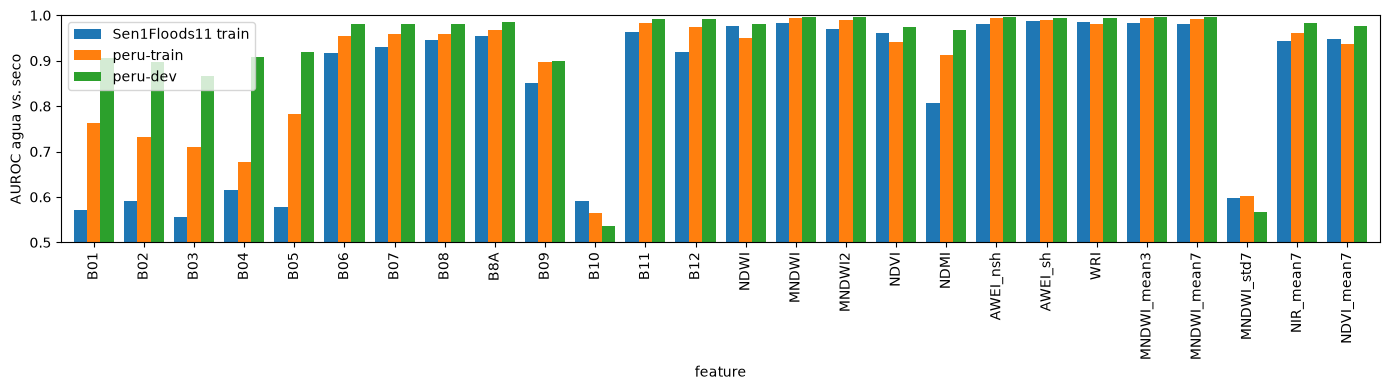

In [3]:
au = pd.read_csv(OUT / "auroc.csv").set_index("feature")
sep = ((au - 0.5).abs() + 0.5).rename(columns={"auroc_s1f11-train": "Sen1Floods11 train", "auroc_peru-train": "peru-train", "auroc_peru-dev": "peru-dev"})
sep = sep[["Sen1Floods11 train", "peru-train", "peru-dev"]]
display(sep.sort_values("peru-dev", ascending=False).round(3))
ax = sep.plot.bar(figsize=(14, 4), width=0.8); ax.set_ylim(0.5, 1.0); ax.set_ylabel("AUROC agua vs. seco")
plt.tight_layout(); plt.show()

## 3. Clasificador por píxel: ¿qué conjunto de características funciona mejor?

**Clasificador.** `HistGradientBoostingClassifier` de scikit-learn, con 200 iteraciones y tasa
de aprendizaje 0.1.

**Entrenamiento.**
- Píxeles al azar con la proporción natural de clases: 600 por recorte de `peru-train` (753
  recortes) o 2 000 por recorte de Sen1Floods11 `train` (252 recortes).
- 3 semillas por configuración; la semilla fija la muestra y el modelo.

**Evaluación.**
- En `peru-dev`, sobre una de cada dos filas y columnas (1/4 de los píxeles).
- Métrica: IoU de agua agrupado sobre todos los píxeles etiquetados. Se reporta la media ± la
  desviación estándar entre semillas.

**Línea base.** Un umbral de MNDWI ajustado con las etiquetas de **entrenamiento**, a diferencia
del umbral "oráculo" ajustado en dev. Como referencia, ya medidos antes en dev:
- MNDWI > 0: IoU 0.486;
- umbral oráculo ajustado en dev (+0.27): 0.925;
- U-Net entrenada en Perú: 0.9415 ± 0.0019;
- U-Net entrenada solo en Sen1Floods11: 0.8364 ± 0.0224.

Fuente: `docs/METHODS_NOTES.md`, entrada del 2026-10-15, "Phase-D starting point".

,train,features,iou_mean,iou_std,precision_mean,precision_std,recall_mean,recall_std
0,peru-train,bands,0.9300,0.0013,0.9695,0.0026,0.9580,0.0014
1,peru-train,indices,0.9127,0.0040,0.9577,0.0015,0.9511,0.0058
2,peru-train,bands+indices,0.9256,0.0033,0.9702,0.0011,0.9527,0.0026
3,peru-train,bands+indices+context,0.9290,0.0046,0.9689,0.0083,0.9576,0.0071
4,s1f11-train,bands,0.7359,0.0181,0.7445,0.0189,0.9847,0.0008
5,s1f11-train,indices,0.7348,0.0092,0.7407,0.0093,0.9892,0.0002
6,s1f11-train,bands+indices,0.7233,0.0070,0.7299,0.0071,0.9876,0.0001
7,s1f11-train,bands+indices+context,0.7126,0.0148,0.7193,0.0151,0.9871,0.0001
8,peru-train,MNDWI > 0.280 (fit on peru-train),0.9237,NaN,0.9709,NaN,0.9500,NaN
9,s1f11-train,MNDWI > 0.150 (fit on s1f11-train),0.8358,NaN,0.8483,NaN,0.9826,NaN


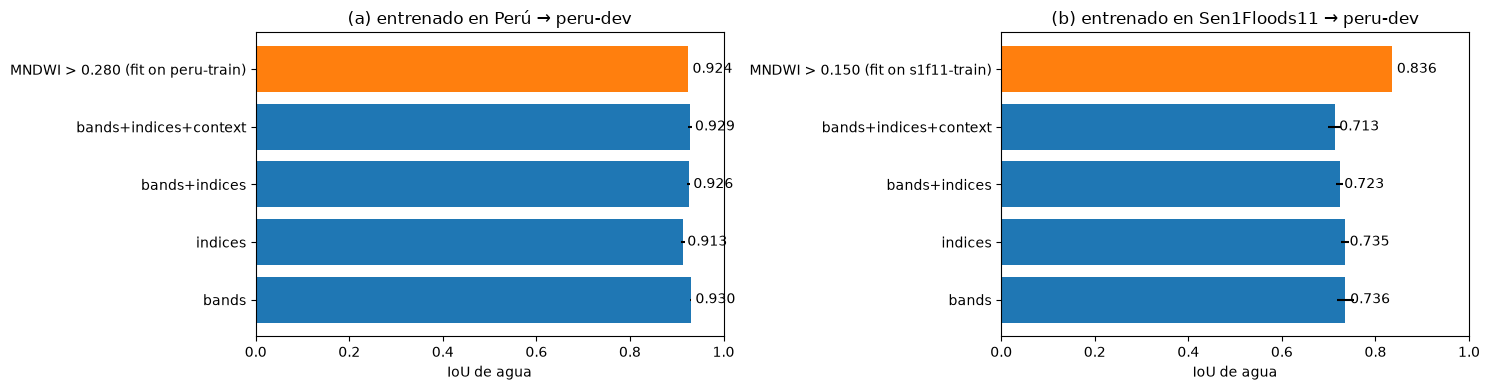

In [4]:
res = pd.read_csv(OUT / "results.csv")
display(res.round(4))
fig, axs = plt.subplots(1, 2, figsize=(15, 4))
for ax, n, t in zip(axs, ["peru-train", "s1f11-train"], ["(a) entrenado en Perú", "(b) entrenado en Sen1Floods11"]):
    r = res[res.train == n].reset_index(drop=True)
    colors = ["tab:orange" if f.startswith("MNDWI") else "tab:blue" for f in r.features]
    ax.barh(range(len(r)), r.iou_mean, xerr=r.iou_std.fillna(0), color=colors)
    ax.set_yticks(range(len(r)), r.features)
    ax.set_xlim(0, 1); ax.set_title(t + " → peru-dev"); ax.set_xlabel("IoU de agua")
    for i, v in enumerate(r.iou_mean): ax.text(v + 0.01, i, f"{v:.3f}", va="center")
plt.tight_layout(); plt.show()

## 4. Importancia por permutación

Se usa el modelo con las 26 características, semilla 0. Se mide cuánto baja el índice de
Jaccard (IoU) en `peru-dev` cuando se desordenan los valores de una característica, con 3
repeticiones sobre 1 200 píxeles al azar por recorte de dev.

Una importancia alta significa que el modelo **depende** de esa característica en Perú.

train,peru-train,s1f11-train
feature,,
AWEI_nsh,0.7182,0.2625
MNDWI2,0.6691,0.0179
MNDWI,0.5796,0.0055
B12,0.4576,0.2817
MNDWI_mean7,0.3476,-0.0052
B11,0.3417,0.0632
MNDWI_mean3,0.0757,0.0021
B05,0.0474,0.0372
B03,0.0229,0.0040


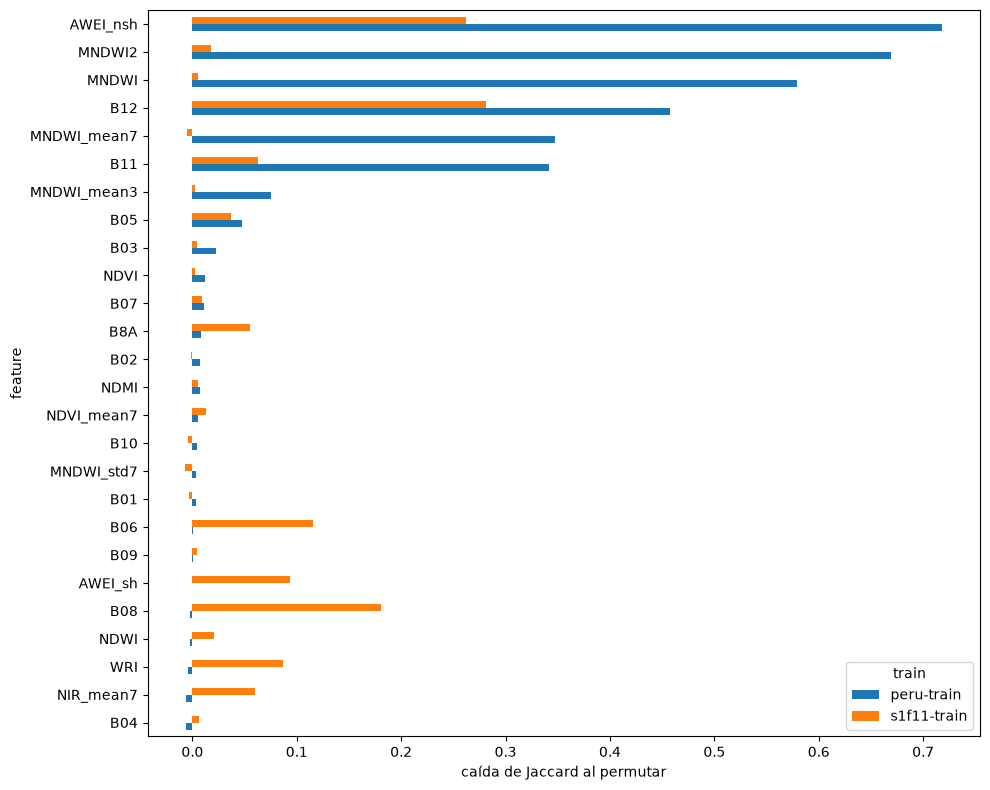

In [5]:
imp = pd.read_csv(OUT / "importance.csv")
piv = imp.pivot(index="feature", columns="train", values="importance").reindex(fe.ALL)
display(piv.sort_values("peru-train", ascending=False).round(4))
ax = piv.sort_values("peru-train").plot.barh(figsize=(10, 8)); ax.set_xlabel("caída de Jaccard al permutar")
plt.tight_layout(); plt.show()

## 5. Conclusiones

Todas las cifras son de `peru-dev`, evaluadas sobre 1/4 de los píxeles, con 3 semillas
(media ± desviación estándar). Fuente: `outputs/feature_engineering/results.csv`.

**(a) Con etiquetas de Perú, las características diseñadas no mejoran al clasificador.**

| Conjunto de características | IoU de agua en `peru-dev` |
|---|---|
| Bandas crudas | 0.930 ± 0.001 |
| Bandas + índices | 0.926 ± 0.003 |
| Bandas + índices + contexto | 0.929 ± 0.005 |
| Solo índices | 0.913 ± 0.004 |

- El *gradient boosting* ya combina las bandas por sí mismo: en Perú, B11 y B12 solas separan
  el agua del desierto con un AUROC cercano a 0.98.
- Un solo umbral de MNDWI ajustado con las etiquetas de `peru-train` (t = 0.28) llega a 0.924.
  Es casi lo mismo que el umbral "oráculo" ajustado en dev (0.925). En Perú 2023, la frontera
  entre agua y suelo seco es casi un umbral de MNDWI.
- La U-Net entrenada en Perú llega a 0.9415. La diferencia con el mejor clasificador por píxel
  (unos 0.01 de IoU) es lo que aporta el contexto espacial que aprende la red. Las ventanas
  de contexto diseñadas (3×3 y 7×7) no recuperan esa diferencia.

**(b) Sin etiquetas de Perú, una característica simple e invariante transfiere mejor que un
modelo flexible.**

| Modelo, entrenado solo con Sen1Floods11 | IoU de agua en `peru-dev` |
|---|---|
| *Gradient boosting*, según el conjunto de características | 0.71 a 0.74 |
| MNDWI > 0.15, umbral ajustado con las etiquetas de Sen1Floods11 | 0.836 |
| U-Net entrenada solo en Sen1Floods11 (medida antes) | 0.836 ± 0.022 |

- Los clasificadores entrenados en Sen1Floods11 tienen recall de 0.98 a 0.99 pero precisión de
  solo 0.72 a 0.74. Confunden el desierto brillante de Perú con agua, el mismo error que
  muestran los modelos profundos sin adaptar.
- La importancia por permutación explica por qué. Estos modelos dependen de bandas crudas
  (B12, B08, B06), cuyo valor cambia entre dominios. En cambio, el modelo entrenado en Perú
  depende sobre todo de índices de agua (AWEI_nsh, MNDWI2, MNDWI).
- Añadir índices y contexto al modelo flexible **no** mejora la transferencia (0.713 a 0.736).
  La flexibilidad le permite aprender la apariencia del suelo seco de Sen1Floods11.
- La separabilidad univariada de los índices de agua es alta y estable entre dominios: AUROC
  de 0.98 en Sen1Floods11 y de 0.997 en `peru-dev` para MNDWI. La de las bandas visibles, en
  cambio, se invierte. En Sen1Floods11 el agua es algo más brillante que el suelo seco en el
  visible; en Perú es más oscura que el desierto.

**Implicaciones para la tesis.**
1. Mantener entradas crudas en los modelos profundos sigue siendo razonable. Con etiquetas del
   dominio, las características diseñadas no añaden información.
2. El problema principal es el **cambio de dominio del suelo seco**, no la falta de
   características. Es lo que atacan los métodos de adaptación de la tesis: la igualación de
   histogramas y FDA.
3. Hay una línea base nueva sin etiquetas peruanas: MNDWI > umbral ajustado en Sen1Floods11.
   Obtiene 0.836 en dev, igual que la U-Net sin adaptar. Como se definió **después** de la
   evaluación única en prueba, no se evaluará en `peru-test`. Queda como resultado
   exploratorio y como trabajo futuro, junto con añadir MNDWI como canal de entrada de la
   U-Net.

**Limitaciones.**
- Solo se evalúa en `peru-dev`, con 1/4 de los píxeles y una sola partición. Las comparaciones
  con la U-Net son aproximadas, porque la U-Net se evaluó sobre todos los píxeles.
- El clasificador es por píxel. La importancia por permutación con características
  correlacionadas reparte la importancia entre ellas.
